****Network exploration****

In [15]:
from pathlib import Path
import pandas as pd
import igraph as ig
import matplotlib.pyplot as plt
import numpy as np
import time, random

In [2]:
DATA = Path('../data')                      # adjust if your new notebook sits somewhere else
edges = pd.read_csv(DATA / 'retweet_network_edges.csv',
                    dtype={'source_account_id': str, 'target_account_id': str,
                           'unresolved_target_tweet_id': str})

# edges with an unknown target account can't be network edges
known = edges.dropna(subset=['target_account_id'])
print(f'{len(edges):,} edge rows -> {len(known):,} with a known target')

# one weighted edge per account pair (weight = number of retweets)
pairs = (known.groupby(['source_account_id', 'target_account_id'], as_index=False)['retweet_count']
              .sum())
              
# Write to NCOL file
ncol_path = DATA / 'retweet_network.ncol'
pairs.to_csv(ncol_path, sep=' ', header=False, index=False)    # lines like: source target weight

1,531,425 edge rows -> 1,522,332 with a known target


In [ ]:
g = ig.read(ncol_path, format='ncol', directed=True)
print(g.summary())
print('self-loops:', sum(g.is_loop()))

g2 = g.copy()
g2.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})
print(g2.summary())

IGRAPH DNW- 755988 1522332 -- 
+ attr: name (v), weight (e)
self-loops: 4038
IGRAPH DNW- 755988 1518294 -- 
+ attr: name (v), weight (e)


**Observations**

Both graphs are directed (D) and named (N), with account IDs as the name attribute.

There are 4038 self loops, which mean that the original tweet is retweeted by the same user

4,038 edges were removed (the self loops) by simplify() (1,522,332 − 1,518,294). That is about 0.3% of the edges.

The typical account has only a couple of ties, and any hubs sit far above that average.

In [31]:
order, size = g2.vcount(), g2.ecount()
in_deg, out_deg = np.array(g2.indegree()), np.array(g2.outdegree())

weak   = g2.connected_components(mode='weak')
strong = g2.connected_components(mode='strong')

summary = pd.Series({
    'order (vertices)': order,
    'size (edges)': size,
    'directed': g2.is_directed(),
    'density': g2.density(),
    'mean in/out-degree': size / order,
    'max in-degree': in_deg.max(),
    'max out-degree': out_deg.max(),
    'accounts that only retweet (in-degree 0)': int((in_deg == 0).sum()),
    'accounts that are only retweeted (out-degree 0)': int((out_deg == 0).sum()),
    'weakly connected components': len(weak),
    'strongly connected components': len(strong),
    'total retweets (sum of weights)': int(sum(g2.es['weight'])),
})
summary.to_frame('value')

,value
order (vertices),755988
size (edges),1518294
directed,True
density,0.000003
mean in/out-degree,2.008357
max in-degree,142106
max out-degree,1301
accounts that only retweet (in-degree 0),686667
accounts that are only retweeted (out-degree 0),40364
weakly connected components,10810


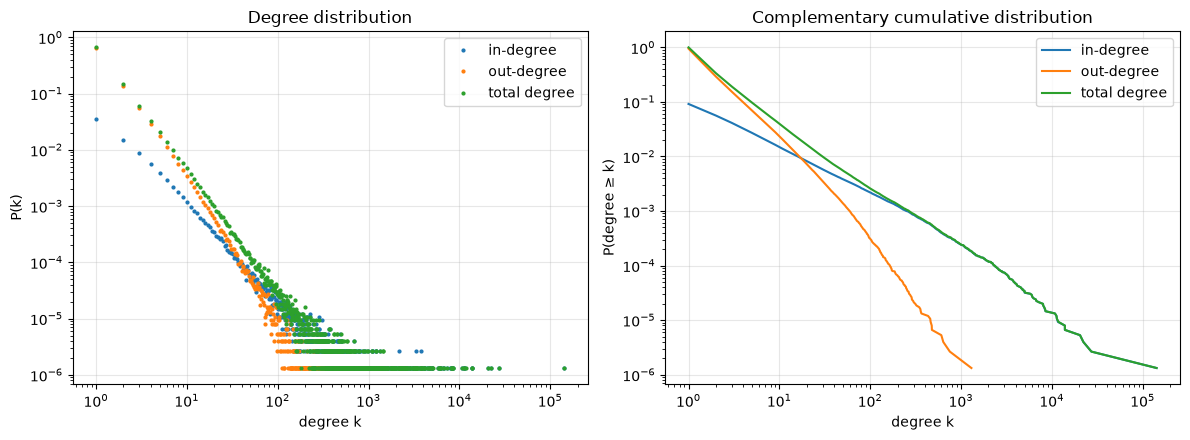

In [32]:
def pk(d):
    """P(degree = k) for k >= 1."""
    counts = np.bincount(d)
    k = np.nonzero(counts)[0]
    k = k[k > 0]
    return k, counts[k] / len(d)

def ccdf(d):
    """P(degree >= k) for k >= 1."""
    counts = np.bincount(d)
    tail = counts[::-1].cumsum()[::-1] / len(d)
    k = np.nonzero(counts)[0]
    k = k[k > 0]
    return k, tail[k]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, d in [('in-degree', in_deg), ('out-degree', out_deg), ('total degree', in_deg + out_deg)]:
    k, p = pk(d);   axes[0].loglog(k, p, '.', ms=4, label=name)
    k, t = ccdf(d); axes[1].loglog(k, t, '-', lw=1.5, label=name)

axes[0].set(xlabel='degree k', ylabel='P(k)', title='Degree distribution')
axes[1].set(xlabel='degree k', ylabel='P(degree ≥ k)', title='Complementary cumulative distribution')
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Observations**

In [33]:

strength = np.array(g2.strength(mode='all', weights='weight'))      # retweets sent + received
el = np.array(g2.get_edgelist())

# how big is the core for different thresholds? aim is around roughly 2,000-20,000 vertices
for t in (5, 10, 20, 50, 100, 200):
    keep = strength >= t
    print(f'strength >= {t:>3}: {keep.sum():>8,} vertices, {(keep[el[:,0]] & keep[el[:,1]]).sum():>9,} edges')

strength >=   5:   88,044 vertices,   647,031 edges
strength >=  10:   38,713 vertices,   429,090 edges
strength >=  20:   16,893 vertices,   262,971 edges
strength >=  50:    5,648 vertices,   117,270 edges
strength >= 100:    2,592 vertices,    54,798 edges
strength >= 200:    1,210 vertices,    19,024 edges


In [34]:
MIN_STRENGTH = 50                                                  # choose from the table above
H = g2.induced_subgraph(np.where(strength >= MIN_STRENGTH)[0].tolist())
H = H.connected_components(mode='weak').giant()                    # drop small detached pieces
print(H.vcount(), 'vertices,', H.ecount(), 'edges')

5424 vertices, 117269 edges


In [35]:
layout_names = ['random', 'circle', 'drl', 'lgl', 'fr']
if H.vcount() <= 3000:
    layout_names.append('kk')                                      # Kamada-Kawai is too slow for large graphs

layouts, times = {}, {}
for name in layout_names:
    random.seed(1)                                                 # same result on re-runs
    t0 = time.perf_counter()
    try:
        layouts[name] = H.layout(name)
    except Exception as e:
        print(name, 'failed:', e); continue
    times[name] = time.perf_counter() - t0
    print(f'{name:9s} {times[name]:7.1f} s')

random        0.0 s
circle        0.0 s
drl          72.7 s
lgl          18.2 s
fr            1.8 s


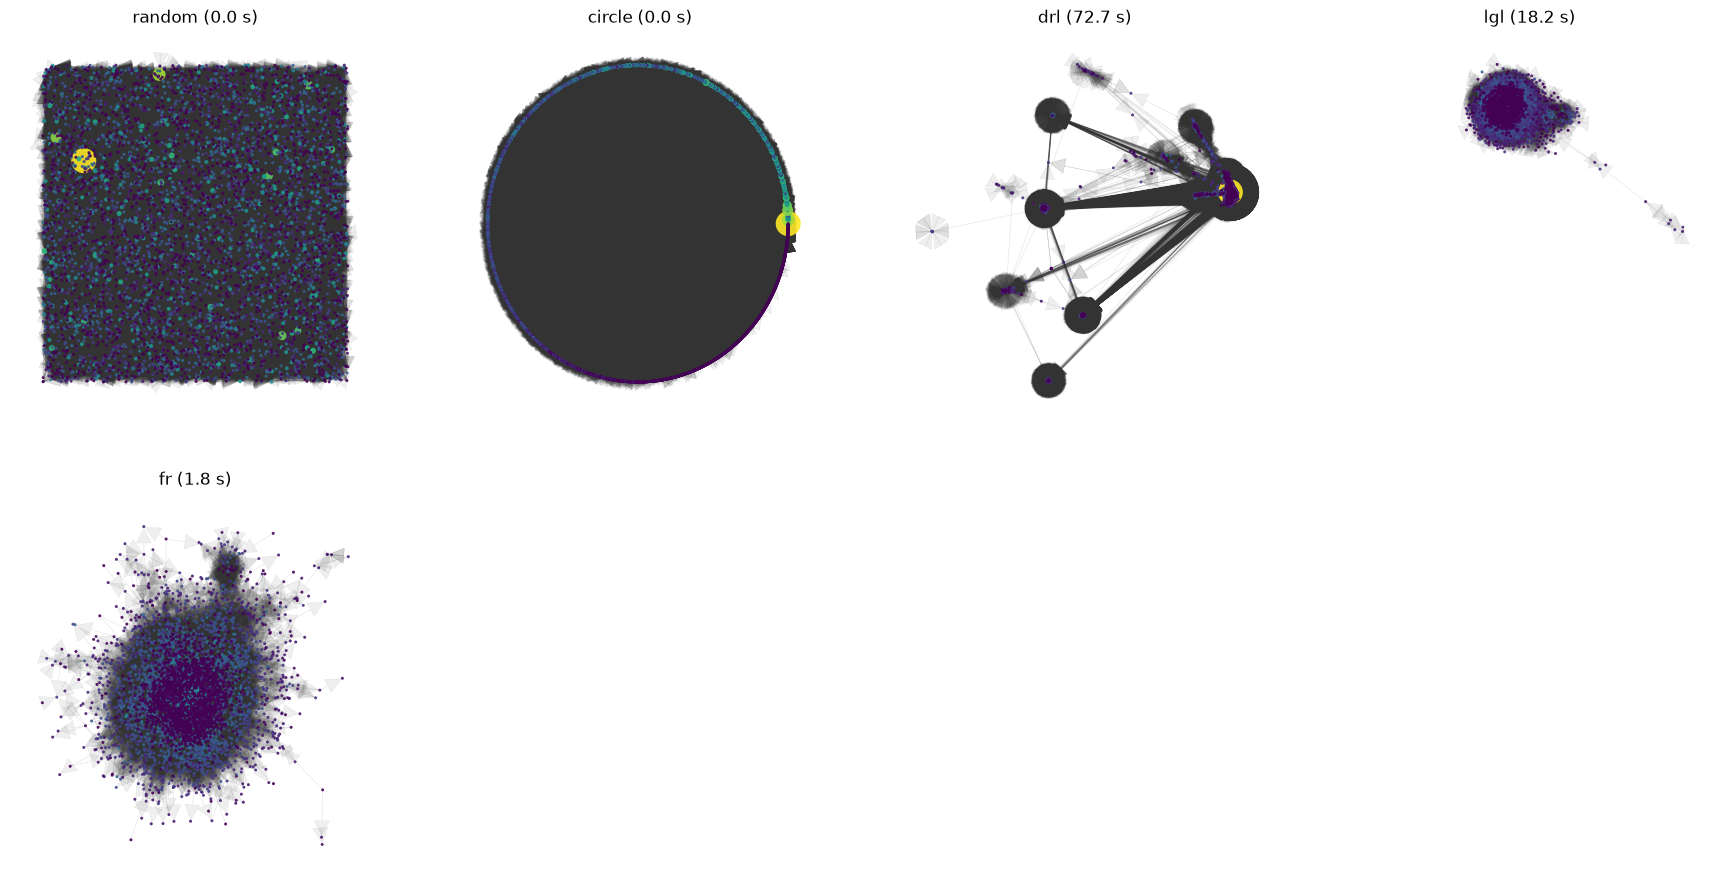

In [36]:
in_str = np.array(H.strength(mode='in', weights='weight'))        # retweets received
size = 3 + 22 * np.sqrt(in_str / in_str.max())
shade = np.log1p(in_str) / np.log1p(in_str).max()
H.vs['color'] = [(*plt.cm.viridis(s)[:3], 0.9) for s in shade]    # bright = much retweeted
H.es['color'] = [(0.2, 0.2, 0.2, 0.08)] * H.ecount()              # very transparent edges

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for ax, name in zip(axes.ravel(), layouts):
    ig.plot(H, target=ax, layout=layouts[name], vertex_size=list(size),
            vertex_frame_width=0, vertex_label=None, edge_width=0.4)
    ax.set_title(f'{name} ({times[name]:.1f} s)')
for ax in axes.ravel()[len(layouts):]: ax.axis('off')
fig.savefig('layouts_compared.png', dpi=200, bbox_inches='tight')
plt.show()

**Observations**

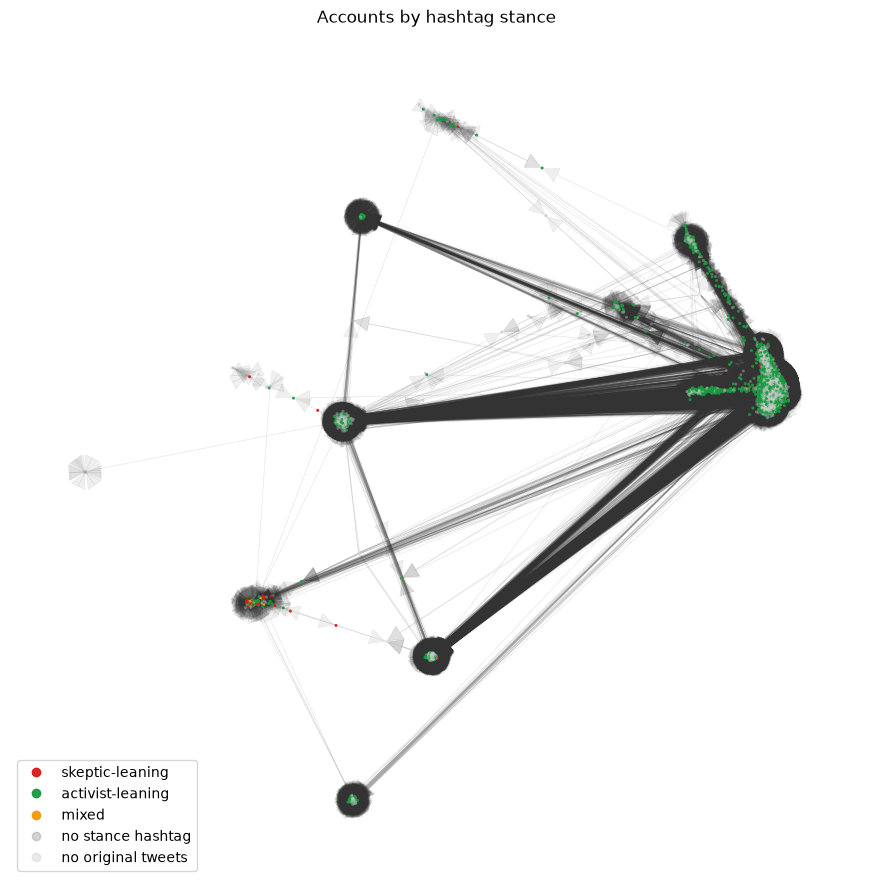

In [37]:
groups = pd.read_csv(DATA / 'account_groups.csv', dtype={'account_id': str}).set_index('account_id')
names = H.vs['name']

stance = groups['hashtag_stance'].reindex(names).fillna('no original tweets')
role   = groups['network_role'].reindex(names).fillna('not in retweet network')

stance_colors = {'skeptic-leaning':  (0.85, 0.10, 0.10, 0.95),
                 'activist-leaning': (0.10, 0.60, 0.25, 0.95),
                 'mixed':            (0.95, 0.60, 0.00, 0.95),
                 'no stance hashtag':(0.65, 0.65, 0.65, 0.50),
                 'no original tweets':(0.80, 0.80, 0.80, 0.40)}

def plot_categories(categories, palette, layout_name, title, fname=None):
    fig, ax = plt.subplots(figsize=(11, 11))
    ig.plot(H, target=ax, layout=layouts[layout_name],
            vertex_color=[palette[c] for c in categories],          # one colour per actor
            vertex_size=list(size), vertex_frame_width=0, vertex_label=None, edge_width=0.4)
    ax.set_title(title)
    ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=col, label=lab)
                       for lab, col in palette.items() if lab in set(categories)], loc='lower left')
    if fname: fig.savefig(fname, dpi=200, bbox_inches='tight')
    plt.show()

plot_categories(stance, stance_colors, 'drl', 'Accounts by hashtag stance', 'network_stance.png')   # use the layout you chose

In [38]:
# how many accounts per category in this plot?
print(stance.value_counts().to_frame('accounts').assign(share=lambda d: (d['accounts'] / d['accounts'].sum()).round(3)))

# who retweets whom, by category (weighted by number of retweets); rows = retweeting group
src, dst = zip(*H.get_edgelist())
mix = pd.crosstab(stance.iloc[list(src)].values, stance.iloc[list(dst)].values,
                  values=H.es['weight'], aggfunc='sum').fillna(0)
display(mix.div(mix.sum(axis=1), axis=0).round(3))

# do like-minded accounts link to each other? (only for accounts that have a stance)
labelled = [i for i, s in enumerate(stance) if s in ('skeptic-leaning', 'activist-leaning', 'mixed')]
sub = H.induced_subgraph(labelled)
codes = pd.Categorical(stance.iloc[labelled]).codes.tolist()
print('nominal assortativity among labelled accounts:', sub.assortativity_nominal(codes, directed=True))

                    accounts  share
hashtag_stance                     
activist-leaning        3388  0.625
no original tweets      1570  0.289
no stance hashtag        434  0.080
skeptic-leaning           24  0.004
mixed                      8  0.001


col_0,activist-leaning,mixed,no original tweets,no stance hashtag,skeptic-leaning
row_0,,,,,
activist-leaning,0.924,0.00,0.035,0.040,0.000
mixed,0.929,0.00,0.014,0.057,0.000
no original tweets,0.915,0.00,0.040,0.045,0.001
no stance hashtag,0.829,0.00,0.036,0.134,0.001
skeptic-leaning,0.744,0.06,0.043,0.060,0.094


nominal assortativity among labelled accounts: 0.13608330123571147


**Observations**